In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

pd.set_option("display.max_columns", None)

print("SilverAI EDA initialized successfully.")

SilverAI EDA initialized successfully.


In [21]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"

intraday_df = pd.read_csv(DATA_DIR / "SI_1m_1098d.csv")
daily_df = pd.read_csv(DATA_DIR / "SI_daily_roll-adjusted.csv")

print("Intraday shape:", intraday_df.shape)
print("Daily shape:", daily_df.shape)

display(intraday_df.head())
display(daily_df.head())

Intraday shape: (1031365, 6)
Daily shape: (7775, 6)


,datetime_et,open,high,low,close,volume
0,2023-11-01 02:09,22.745,22.755,22.745,22.755,21
1,2023-11-01 02:10,22.750,22.755,22.750,22.755,23
2,2023-11-01 02:11,22.760,22.760,22.745,22.755,70
3,2023-11-01 02:12,22.755,22.765,22.755,22.760,20
4,2023-11-01 02:13,22.765,22.770,22.760,22.770,31


,date,open,high,low,close,volume
0,1995-11-29,9.269814,9.296124,9.138265,9.150543,26462
1,1995-11-30,9.164575,9.252274,9.059336,9.238242,16144
2,1995-12-01,9.252274,9.278584,9.182115,9.194393,9022
3,1995-12-04,9.208424,9.225964,9.147035,9.185623,7118
4,1995-12-05,9.190885,9.278584,9.164575,9.255782,10728


In [22]:
def prepare_market_data(df, timestamp_col):
    df = df.copy()

    df.columns = [
        str(col).strip().lower() for col in df.columns
    ]

    timestamp_col = timestamp_col.lower()

    df = df.rename(
        columns={timestamp_col: "timestamp"}
    )

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        errors="coerce"
    )

    if df["timestamp"].dt.tz is None:
        df["timestamp"] = df["timestamp"].dt.tz_localize(
            "America/New_York",
            ambiguous="NaT",
            nonexistent="NaT"
        )
    else:
        df["timestamp"] = df["timestamp"].dt.tz_convert(
            "America/New_York"
        )

    for col in ["open", "high", "low", "close", "volume"]:
        if col in df.columns:
            df[col] = pd.to_numeric(
                df[col],
                errors="coerce"
            )

    df = df.sort_values("timestamp").reset_index(drop=True)

    return df


intraday = prepare_market_data(
    intraday_df,
    "datetime_et"
)

daily = prepare_market_data(
    daily_df,
    "date"
)

print("Intraday prepared:", intraday.shape)
print("Daily prepared:", daily.shape)

display(intraday.head())

Intraday prepared: (1031365, 6)
Daily prepared: (7775, 6)


,timestamp,open,high,low,close,volume
0,2023-11-01 02:09:00-04:00,22.745,22.755,22.745,22.755,21
1,2023-11-01 02:10:00-04:00,22.750,22.755,22.750,22.755,23
2,2023-11-01 02:11:00-04:00,22.760,22.760,22.745,22.755,70
3,2023-11-01 02:12:00-04:00,22.755,22.765,22.755,22.760,20
4,2023-11-01 02:13:00-04:00,22.765,22.770,22.760,22.770,31


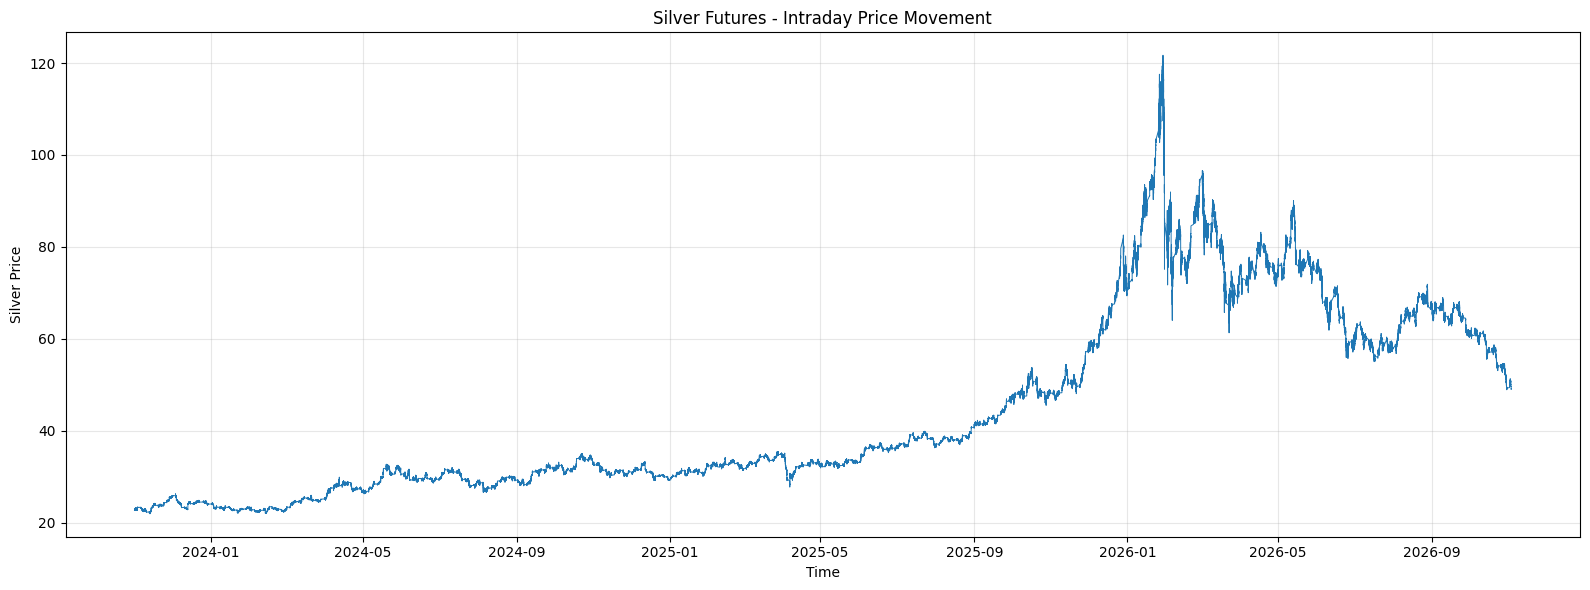

In [23]:
plt.figure(figsize=(16, 6))

plt.plot(
    intraday["timestamp"],
    intraday["close"],
    linewidth=0.7
)

plt.title("Silver Futures - Intraday Price Movement")
plt.xlabel("Time")
plt.ylabel("Silver Price")
plt.tight_layout()
plt.show()

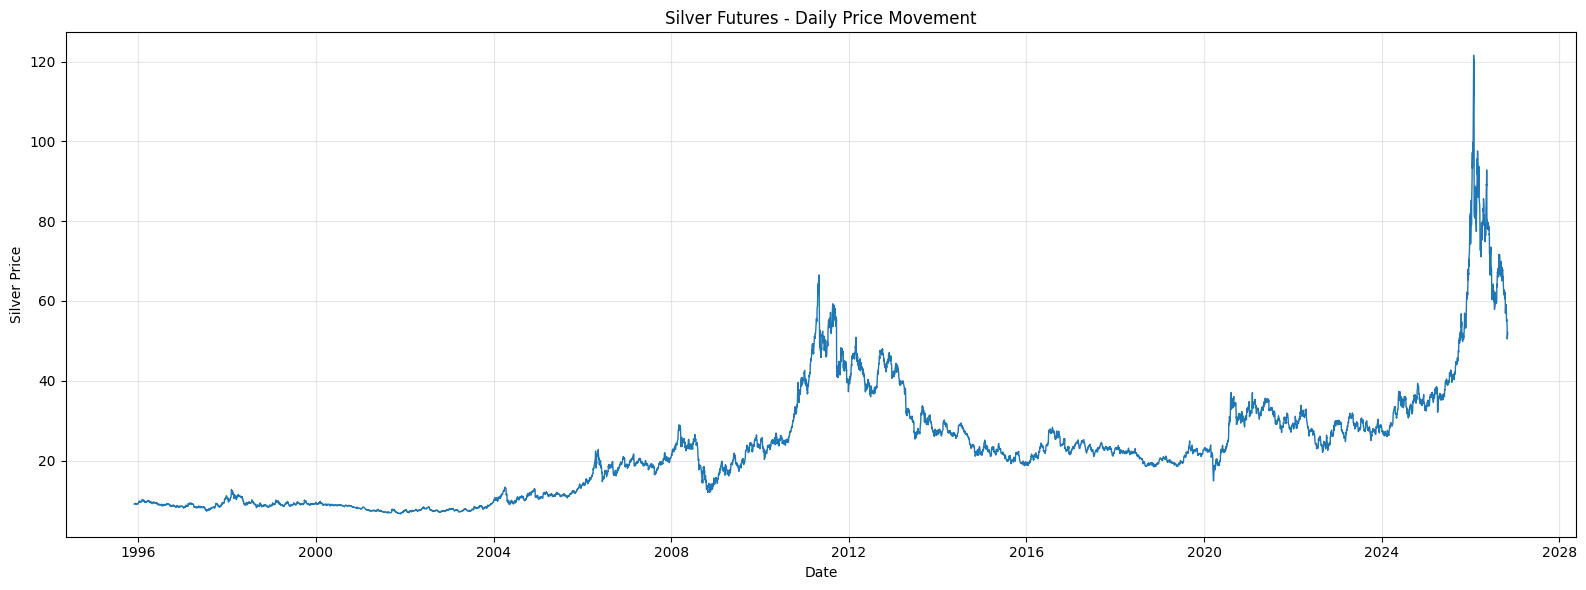

In [24]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily["timestamp"],
    daily["close"],
    linewidth=1
)

plt.title("Silver Futures - Daily Price Movement")
plt.xlabel("Date")
plt.ylabel("Silver Price")
plt.tight_layout()
plt.show()

In [25]:
intraday["return"] = (
    intraday["close"].pct_change() * 100
)

daily["return"] = (
    daily["close"].pct_change() * 100
)

display(intraday[["timestamp", "close", "return"]].head(10))

,timestamp,close,return
0,2023-11-01 02:09:00-04:00,22.755,NaN
1,2023-11-01 02:10:00-04:00,22.755,0.000000
2,2023-11-01 02:11:00-04:00,22.755,0.000000
3,2023-11-01 02:12:00-04:00,22.760,0.021973
4,2023-11-01 02:13:00-04:00,22.770,0.043937
5,2023-11-01 02:14:00-04:00,22.770,0.000000
6,2023-11-01 02:15:00-04:00,22.765,-0.021959
7,2023-11-01 02:16:00-04:00,22.780,0.065891
8,2023-11-01 02:17:00-04:00,22.780,0.000000
9,2023-11-01 02:18:00-04:00,22.785,0.021949


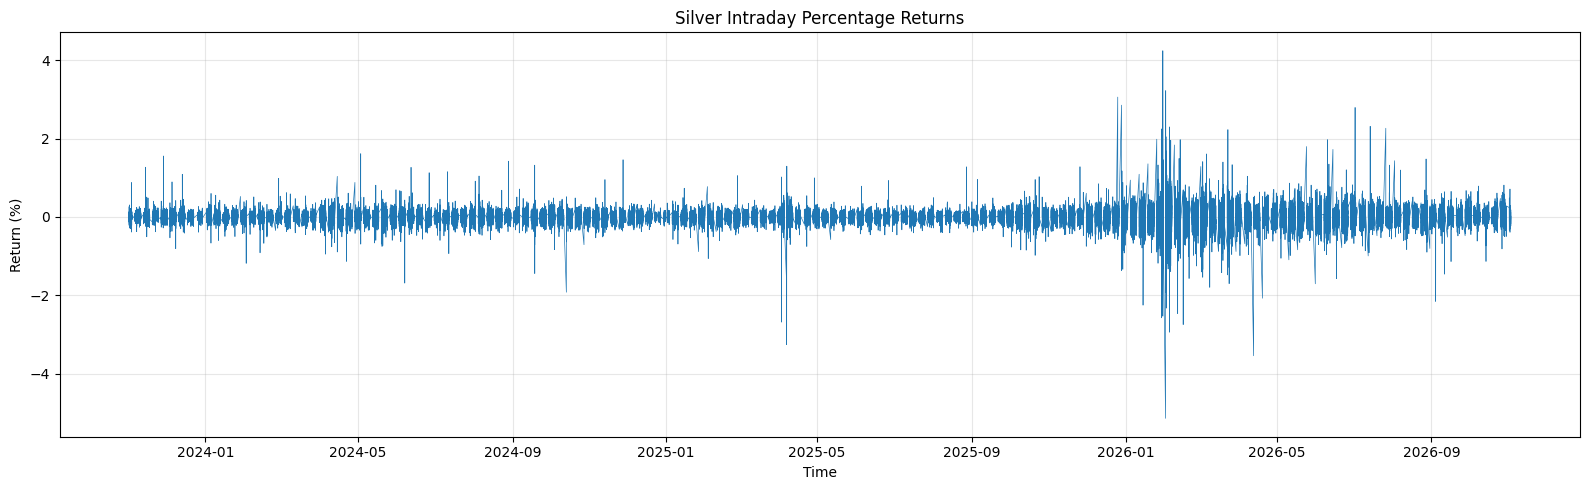

In [26]:
plt.figure(figsize=(16, 5))

plt.plot(
    intraday["timestamp"],
    intraday["return"],
    linewidth=0.5
)

plt.title("Silver Intraday Percentage Returns")
plt.xlabel("Time")
plt.ylabel("Return (%)")

plt.tight_layout()
plt.show()

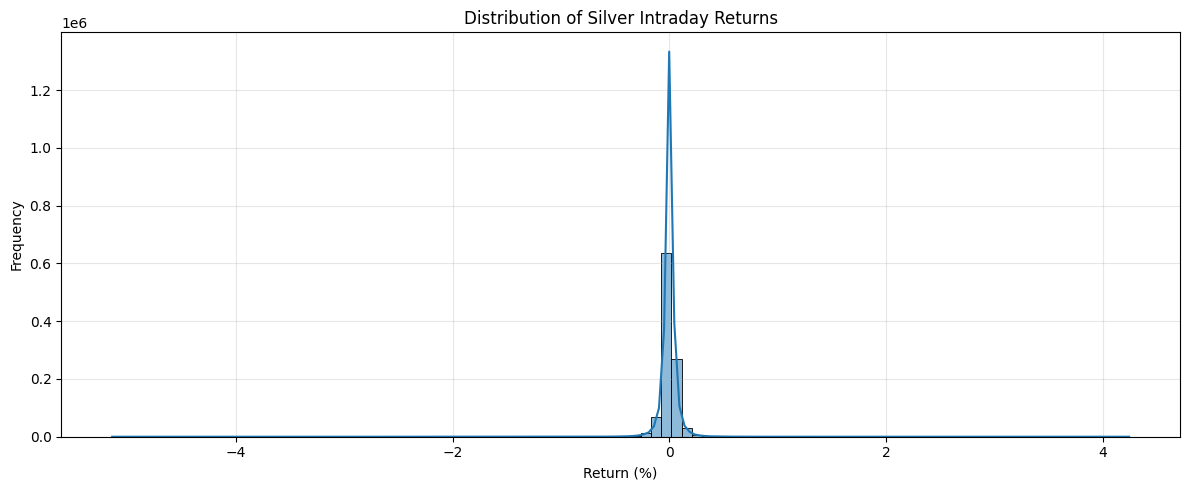

In [27]:
returns = intraday["return"].dropna()

plt.figure(figsize=(12, 5))

sns.histplot(
    returns,
    bins=100,
    kde=True
)

plt.title("Distribution of Silver Intraday Returns")
plt.xlabel("Return (%)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [28]:
print("RETURN STATISTICS")

display(
    intraday["return"].describe().to_frame("Value")
)

print("Skewness:", intraday["return"].skew())
print("Kurtosis:", intraday["return"].kurt())

RETURN STATISTICS


,Value
count,1.031364e+06
mean,1.046345e-04
std,7.762215e-02
min,-5.143695e+00
25%,-2.772387e-02
50%,0.000000e+00
75%,2.923549e-02
max,4.245964e+00


Skewness: -0.516020866502427
Kurtosis: 104.1310748821772


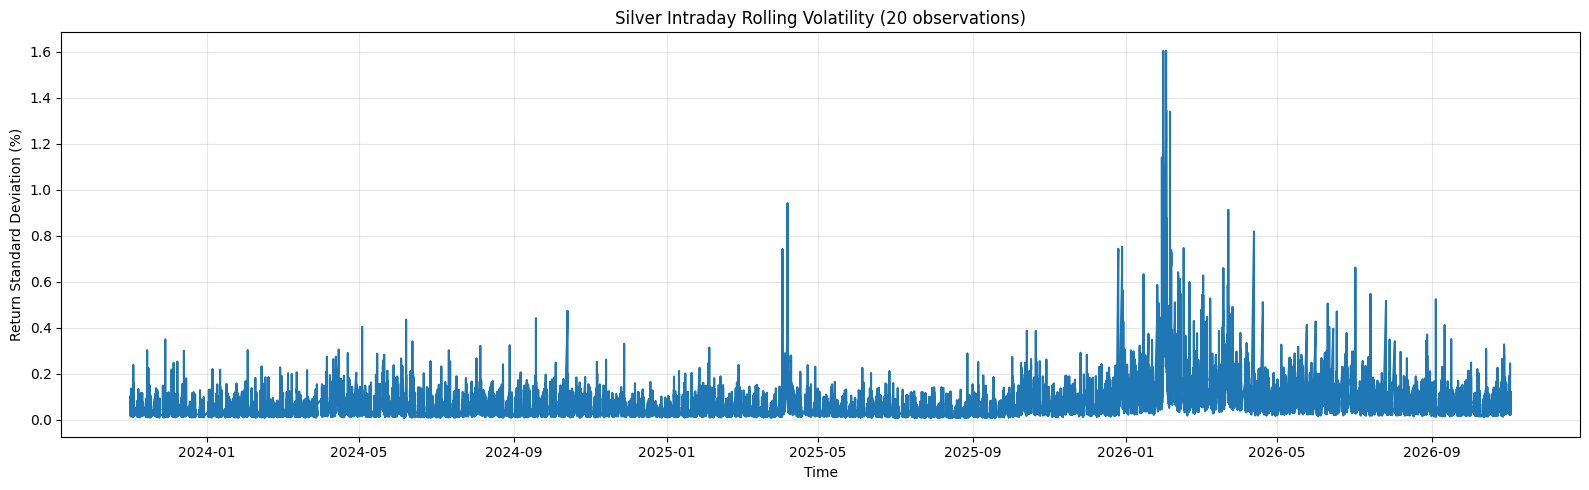

In [29]:
intraday["volatility_20"] = (
    intraday["return"]
    .rolling(window=20)
    .std()
)

plt.figure(figsize=(16, 5))

plt.plot(
    intraday["timestamp"],
    intraday["volatility_20"]
)

plt.title("Silver Intraday Rolling Volatility (20 observations)")
plt.xlabel("Time")
plt.ylabel("Return Standard Deviation (%)")

plt.tight_layout()
plt.show()

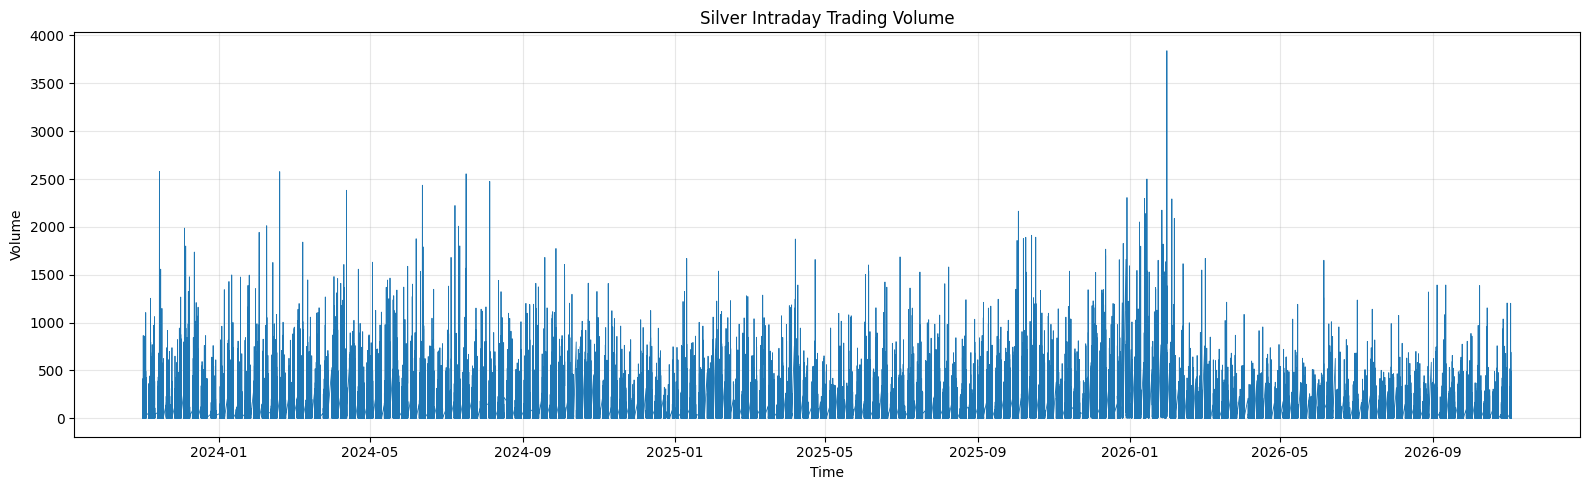

Volume statistics:


count    1.031365e+06
mean     4.444585e+01
std      7.695075e+01
min      0.000000e+00
25%      8.000000e+00
50%      2.000000e+01
75%      4.900000e+01
max      3.840000e+03
Name: volume, dtype: float64

In [30]:
if "volume" in intraday.columns:

    plt.figure(figsize=(16, 5))

    plt.plot(
        intraday["timestamp"],
        intraday["volume"],
        linewidth=0.6
    )

    plt.title("Silver Intraday Trading Volume")
    plt.xlabel("Time")
    plt.ylabel("Volume")

    plt.tight_layout()
    plt.show()

    print("Volume statistics:")
    display(intraday["volume"].describe())
else:
    print("Volume column unavailable.")

In [31]:
intraday["hour"] = intraday["timestamp"].dt.hour

intraday["day_of_week"] = (
    intraday["timestamp"].dt.day_name()
)

display(
    intraday[
        ["timestamp", "hour", "day_of_week", "close"]
    ].head()
)

,timestamp,hour,day_of_week,close
0,2023-11-01 02:09:00-04:00,2,Wednesday,22.755
1,2023-11-01 02:10:00-04:00,2,Wednesday,22.755
2,2023-11-01 02:11:00-04:00,2,Wednesday,22.755
3,2023-11-01 02:12:00-04:00,2,Wednesday,22.760
4,2023-11-01 02:13:00-04:00,2,Wednesday,22.770


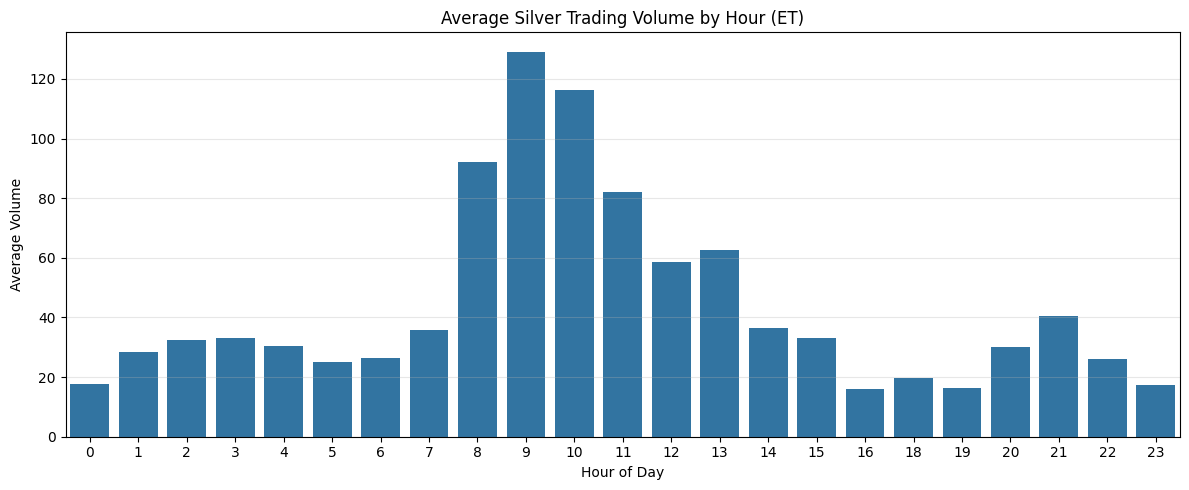

In [32]:
if "volume" in intraday.columns:

    hourly_volume = (
        intraday.groupby("hour")["volume"]
        .mean()
    )

    plt.figure(figsize=(12, 5))

    sns.barplot(
        x=hourly_volume.index,
        y=hourly_volume.values
    )

    plt.title("Average Silver Trading Volume by Hour (ET)")
    plt.xlabel("Hour of Day")
    plt.ylabel("Average Volume")

    plt.tight_layout()
    plt.show()
    

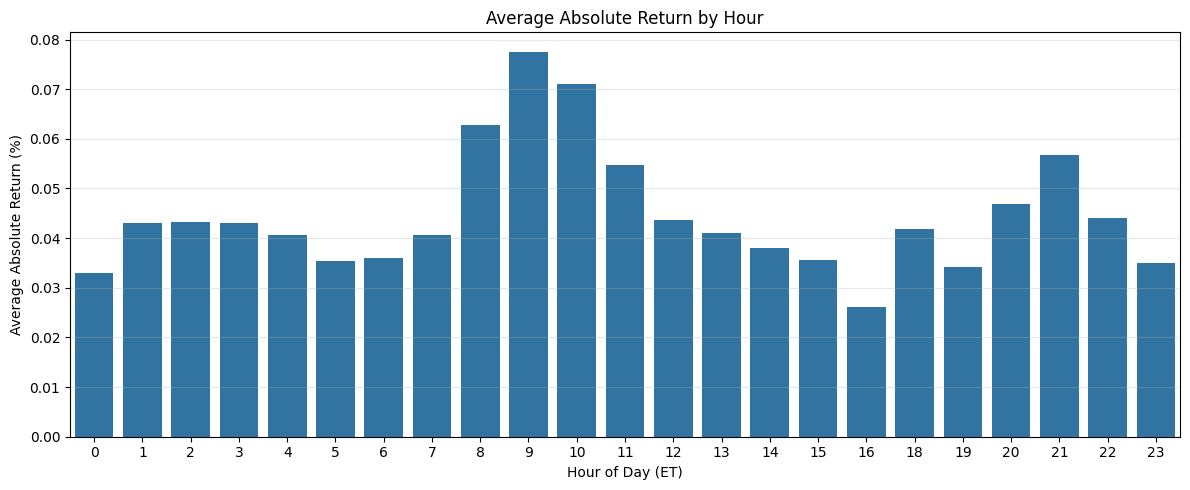

In [33]:
hourly_movement = (
    intraday.groupby("hour")["return"]
    .apply(lambda x: x.abs().mean())
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_movement.index,
    y=hourly_movement.values
)

plt.title("Average Absolute Return by Hour")
plt.xlabel("Hour of Day (ET)")
plt.ylabel("Average Absolute Return (%)")

plt.tight_layout()
plt.show()

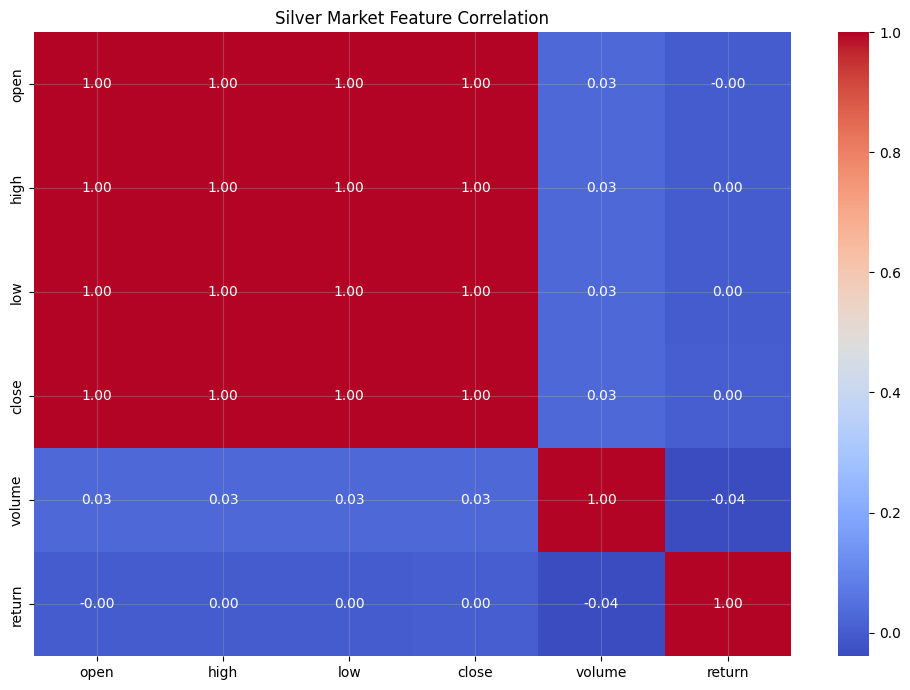

In [34]:
corr_cols = [
    col for col in
    ["open", "high", "low", "close", "volume", "return"]
    if col in intraday.columns
]

correlation = intraday[corr_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Silver Market Feature Correlation")

plt.tight_layout()
plt.show()

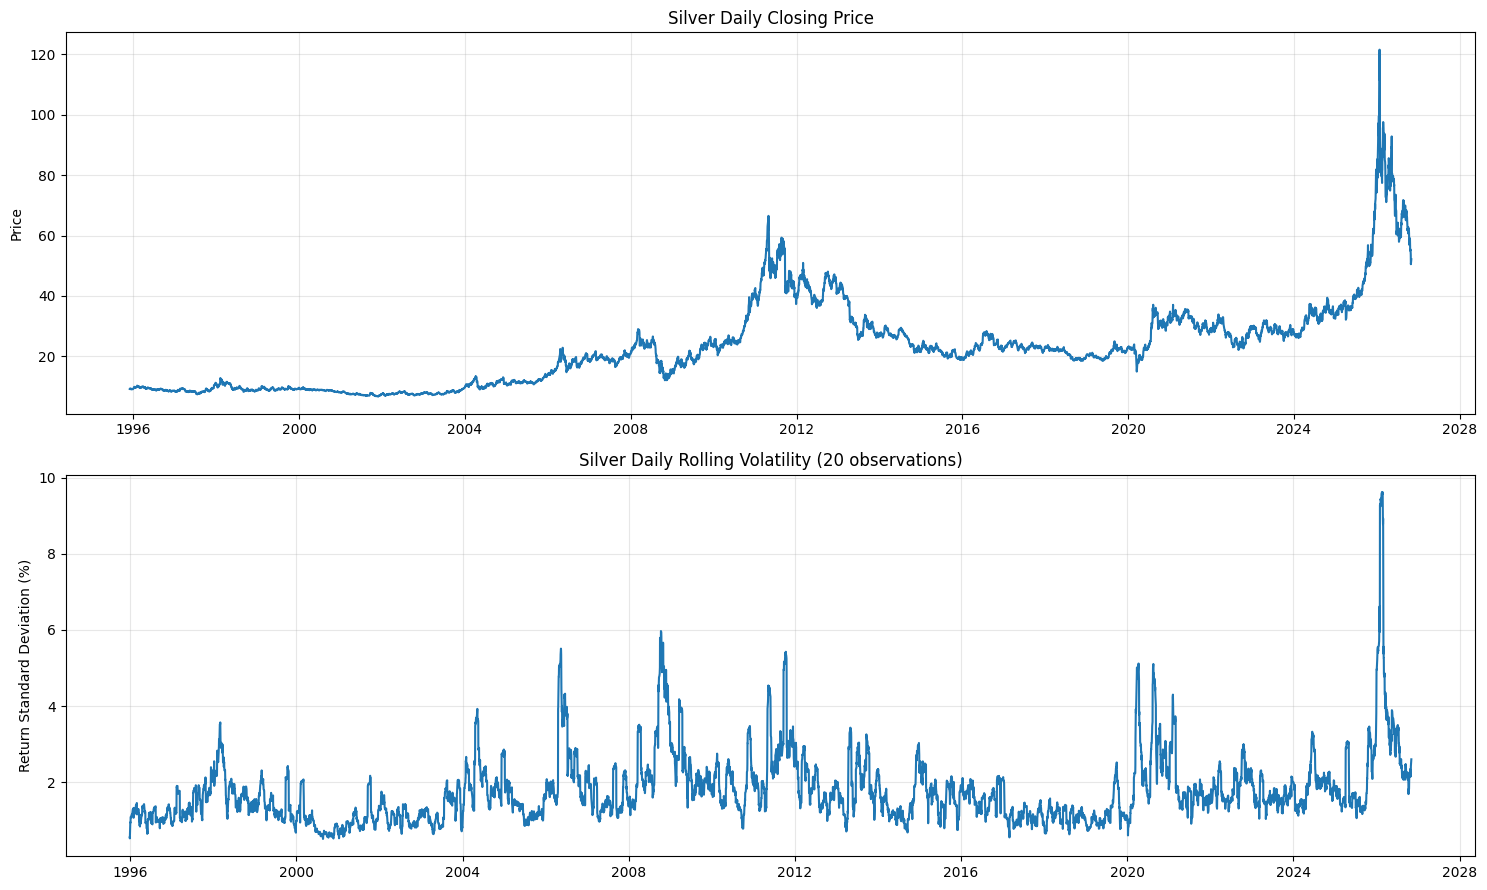

In [35]:
daily["return"] = daily["close"].pct_change() * 100

daily["volatility_20"] = (
    daily["return"].rolling(20).std()
)

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

axes[0].plot(
    daily["timestamp"],
    daily["close"]
)

axes[0].set_title("Silver Daily Closing Price")
axes[0].set_ylabel("Price")

axes[1].plot(
    daily["timestamp"],
    daily["volatility_20"]
)

axes[1].set_title("Silver Daily Rolling Volatility (20 observations)")
axes[1].set_ylabel("Return Standard Deviation (%)")

plt.tight_layout()
plt.show()

In [36]:
intraday["candle_body"] = (
    intraday["close"] - intraday["open"]
).abs()

intraday["candle_range"] = (
    intraday["high"] - intraday["low"]
)

intraday["body_to_range"] = (
    intraday["candle_body"] /
    intraday["candle_range"].replace(0, np.nan)
)

display(
    intraday[
        ["open", "high", "low", "close",
         "candle_body", "candle_range", "body_to_range"]
    ].head(10)
)

,open,high,low,close,candle_body,candle_range,body_to_range
0,22.745,22.755,22.745,22.755,0.010,0.010,1.000000
1,22.750,22.755,22.750,22.755,0.005,0.005,1.000000
2,22.760,22.760,22.745,22.755,0.005,0.015,0.333333
3,22.755,22.765,22.755,22.760,0.005,0.010,0.500000
4,22.765,22.770,22.760,22.770,0.005,0.010,0.500000
5,22.770,22.790,22.770,22.770,0.000,0.020,0.000000
6,22.770,22.770,22.765,22.765,0.005,0.005,1.000000
7,22.770,22.785,22.770,22.780,0.010,0.015,0.666667
8,22.780,22.785,22.780,22.780,0.000,0.005,0.000000
9,22.785,22.790,22.780,22.785,0.000,0.010,0.000000


In [37]:
time_gaps = (
    intraday["timestamp"]
    .diff()
    .dropna()
)

print("Most common time intervals:")
display(
    time_gaps.value_counts().head(15).to_frame("Frequency")
)

print("\nIntervals greater than one minute:")
print((time_gaps > pd.Timedelta(minutes=1)).sum())

Most common time intervals:


,Frequency
timestamp,
0 days 00:01:00,1004779
0 days 00:02:00,20980
0 days 00:03:00,3439
0 days 00:04:00,894
0 days 01:01:00,593
0 days 00:05:00,272
2 days 01:01:00,138
0 days 00:06:00,100
0 days 00:07:00,37



Intervals greater than one minute:
26578


In [39]:
print("-" * 60)
print("SILVERAI - EDA SUMMARY")
print("-" * 60)

print("\nINTRADAY DATA")
print("Observations:", len(intraday))
print("Average closing price:", intraday["close"].mean())
print("Maximum closing price:", intraday["close"].max())
print("Minimum closing price:", intraday["close"].min())
print("Average absolute return:", intraday["return"].abs().mean())
print("Return standard deviation:", intraday["return"].std())

print("\nDAILY DATA")
print("Observations:", len(daily))
print("Average closing price:", daily["close"].mean())
print("Maximum closing price:", daily["close"].max())
print("Minimum closing price:", daily["close"].min())
print("Daily return standard deviation:", daily["return"].std())

print("\nEDA COMPLETED SUCCESSFULLY.")

------------------------------------------------------------
SILVERAI - EDA SUMMARY
------------------------------------------------------------

INTRADAY DATA
Observations: 1031365
Average closing price: 44.25186336647726
Maximum closing price: 121.695
Minimum closing price: 21.93
Average absolute return: 0.044809457714058136
Return standard deviation: 0.07762214645731892

DAILY DATA
Observations: 7775
Average closing price: 22.923956501093247
Maximum closing price: 121.584215
Minimum closing price: 6.66539
Daily return standard deviation: 2.0001590415803445

EDA COMPLETED SUCCESSFULLY.
